# Optional compression of the joint shear vector

The joint measurement has 400 two-point entries, the shear-correlation block
$d_2=\xi_\pm$, and 80 three-point entries, the aperture-skewness block
$d_3=\langle M_\mathrm{ap}^3\rangle$. A likelihood can keep all 480 entries.
Compression replaces them by fixed linear combinations, which helps when
matching a published compressed analysis or when testing covariance
requirements.

The notebook reads the numerical derivative arrays of the saved TATT
demonstration archive; it runs no CAMB or physical calculation, and the archive
records the input hash, the fiducial point and every trained parameter name.
One limit governs everything below: the archive does not certify its
derivatives as converged, and a Fisher identity can close even for inaccurate
derivatives.

The comparison covers ordinary xi-only MOPED and a xi-only compression that
keeps the joint local Gaussian Fisher matrix, followed by the separate
finite-simulation likelihood. Neither a local Fisher identity nor that
likelihood comparison reproduces the posterior of Gomes et al.
(arXiv:2601.09133). [The statistical guide](COMPRESSION.md) states the
assumptions and credits.

**Model and data.** The training inputs come from one archive:

| Choice | Value |
| --- | --- |
| Input archive | `runs/y3_tatt_measured_edge_demo_fisher.npz` (hash printed on load) |
| Derivatives | the archive's `derivatives_h2` field, at its recorded fiducial |
| Training metric | the archive's `fiducial_covariance`; a diagonal pilot for the independent basis |
| Parameters | 20: $\Omega_m$, $\sigma_8$, $\Omega_b$, $h$, $n_s$, the TATT set $A_1$, $\eta_1$, $A_2$, $\eta_2$, $b_\mathrm{TA}$, the shear calibrations $m_{1\ldots4}$, the photo-z shifts $\Delta z_{1\ldots4}$, $w_0$, $w_a$ |
| Pilot noise | $10^{-4}$ per $\xi_\pm$ row, $10^{-8}$ per $M_\mathrm{ap}^3$ row |
| Mock count | $N_s=796$ for the finite-simulation demonstration |
| Saved bases | `runs/conditional_xi_compression.npz`, `runs/independent_pilot_compression.npz` |
| Threads | one BLAS worker |

Words used throughout:

- **MOPED** (Massively Optimized Parameter Estimation and Data compression,
  [Heavens, Jimenez and Lahav, arXiv:astro-ph/9911102](https://arxiv.org/abs/astro-ph/9911102))
  compresses a data vector to one linear combination per parameter, chosen so
  the compressed vector keeps the Fisher information of the original under the
  training covariance.
- A **derivative column** is the change of the mean prediction per unit change
  of one parameter; the **Fisher matrix** $F=D^\mathsf{T}C^{-1}D$ measures the
  local Gaussian information of derivatives $D$ under covariance $C$.
- **Whitening** multiplies a vector by $L^{-1}$, where $C=LL^\mathsf{T}$ is the
  Cholesky factorization, so its entries lose their units and correlations.
- The **Hartlap factor**
  ([Hartlap, Simon and Schneider, arXiv:astro-ph/0608064](https://arxiv.org/abs/astro-ph/0608064))
  rescales an inverted sample covariance by $(N_s-N_d-2)/(N_s-1)$ to undo the
  inversion bias; the finite-simulation density below replaces that rescaling
  and must not be combined with it.
- The **Percival prescription** ([Percival, Friedrich, Sellentin and Heavens,
  arXiv:2108.10402](https://arxiv.org/abs/2108.10402)) is the posterior density
  for a sample covariance from $N_s$ independent Gaussian mocks, with an
  exponent that depends on the kept data entries and fitted parameters.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
                 "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS", "OMP_NUM_THREADS"):
    os.environ[variable] = "1"
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
from scipy.linalg import solve_triangular
import matplotlib
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

project = Path.cwd()
if not (project / "python" / "des3pcf").is_dir():
    raise RuntimeError("Open this notebook with projects/des_3pcf as its directory.")
sys.path.insert(0, str(project / "python"))
from des3pcf.compression import fit_compression, load_compression
from des3pcf.likelihood import FiniteSimulationLikelihood
from des3pcf.survey import SurveyRows
thread_limits = threadpool_limits(limits=1, user_api="blas")

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'


## The cross-covariance changes which xi combinations matter

Write the fixed covariance in blocks $C_{22},C_{23},C_{33}$ and the derivative
matrix as $D_2,D_3$, with 2 marking the two-point block and 3 the three-point
block. A derivative column is the change of the mean per unit parameter. A row
with zero mean response can still improve a joint constraint, because it can
trace a noise fluctuation that it shares with another observable.

For example, let $D_2=(1,0)^\mathsf{T}$, $D_3=1$, $C_{22}=I$,
$C_{23}=(0,r)^\mathsf{T}$ and $C_{33}=1$. Ordinary xi-only MOPED keeps only the
first xi row and discards the second row, the one that traces the three-point
noise. The full amplitude information is $2+r^2/(1-r^2)$; the compressed vector
keeps only 2.

To keep the joint information, first form the conditional covariance and
derivative,

$$
S=C_{22}-C_{23}C_{33}^{-1}C_{32},\qquad
J=D_2-C_{23}C_{33}^{-1}D_3.
$$

With $S=LL^\mathsf{T}$, choose orthonormal columns $Q$ spanning $L^{-1}J$. The
xi weights are $W=Q^\mathsf{T}L^{-1}$. Apply $T=\operatorname{diag}(W,I)$ to the
data and to every prediction, and use $TCT^\mathsf{T}$ including its cross
block. The number of kept xi combinations is the numerical rank of the trained
responses, and every varied nuisance parameter must enter the training.

In [2]:
toy_covariance = np.array([[1., 0., 0.], [0., 1., .6], [0., .6, 1.]])
toy_derivatives = np.array([[1.], [0.], [1.]])
for mode in ("xi_moped", "conditional_xi", "joint"):
    basis = fit_compression(
        covariance=toy_covariance, derivatives=toy_derivatives,
        labels=["xi1", "xi2", "map3"], kind=["xip", "xim", "map3"],
        mode=mode, metadata={"source": "explicit three-row example"},
    )
    response = basis.apply(values=toy_derivatives)
    reduced = basis.covariance(values=toy_covariance)
    information = float((response.T @ np.linalg.solve(reduced, response))[0, 0])
    print(mode, "retained rows:", basis.matrix.shape[0], "information:", information)


xi_moped retained rows: 2 information: 2.0
conditional_xi retained rows: 2 information: 2.5625
joint retained rows: 1 information: 2.5625


## Train on the archived arrays

The calculation below preserves the local information of the archive's
derivative array. It cannot restore information absent from an inaccurate
derivative or from a parameter left out of the training: the fit happens once,
at the recorded fiducial, so a sampled feedback amplitude added later needs its
own derivative and a fresh basis.

The first three bases use the archive's covariance as their training metric,
which suits the fixed-Gaussian algebra demonstration; the finite-simulation
prescription below gets its own basis instead. That pilot basis trains on a
fixed diagonal teaching covariance with noise scales $10^{-4}$ for xi and
$10^{-8}$ for the aperture rows, numbers chosen to expose the mixed units, not
to predict a survey covariance.

In [3]:
archive = project / "runs" / "y3_tatt_measured_edge_demo_fisher.npz"
if not archive.is_file():
    raise FileNotFoundError("Prepare the TATT Fisher example before running this notebook.")
archive_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
with np.load(archive, allow_pickle=False) as saved:
    covariance = saved["fiducial_covariance"].copy()
    derivatives = saved["derivatives_h2"].copy()
    labels = saved["row_labels"].copy()
    kinds = saved["row_kind"].copy()
    names = saved["parameter_names"].tolist()
    mean = saved["mean"].copy()
    prior_fisher = saved["fisher_prior"].copy()
    row_bins = saved["row_bins"].copy()
    row_angles = saved["row_angles_radians"].copy()
    archive_metadata = json.loads(str(saved["metadata_json"].item()))
fiducial = dict(archive_metadata["configuration"]["parameters"])
fiducial.update(archive_metadata["configuration"]["ia"])
training = {
    "archive": str(archive.relative_to(project)),
    "archive_sha256": archive_hash,
    "parameter_names": names,
    "fiducial": fiducial,
    "derivative_field": "derivatives_h2",
    "covariance_field": "fiducial_covariance",
    "covariance_training_independent": False,
    "interpretation": "historical numerical arrays; no current-model accuracy claim",
}
bases = {}
for mode in ("xi_moped", "conditional_xi", "joint"):
    bases[mode] = fit_compression(
        covariance=covariance, derivatives=derivatives, labels=labels,
        kind=kinds, mode=mode, metadata=training,
    )
    print(mode, "output rows:", bases[mode].matrix.shape[0],
          "response rank:", bases[mode].metadata["rank"])
print("Input:", archive_hash, "parameters:", names)


xi_moped output rows: 100 response rank: 20
conditional_xi output rows: 100 response rank: 20
joint output rows: 20 response rank: 20
Input: fcaad62d7a4c89f47114e944f0dde4b906055889526123eb51b321577b1142d6 parameters: ['omega_m', 'sigma8', 'omega_b', 'h', 'ns', 'a1', 'eta1', 'a2', 'eta2', 'bta', 'm1', 'm2', 'm3', 'm4', 'dz1', 'dz2', 'dz3', 'dz4', 'w0', 'wa']


In [4]:
def local_fisher(matrix, response):
    """Whiten derivatives before forming their local Gaussian information."""
    lower = np.linalg.cholesky(matrix)
    whitened = solve_triangular(a=lower, b=response, lower=True)
    return whitened.T @ whitened

full_information = local_fisher(matrix=covariance, response=derivatives)
normalization = np.sqrt(np.diag(full_information))
information = {}
for mode, basis in bases.items():
    information[mode] = local_fisher(
        matrix=basis.covariance(values=covariance),
        response=basis.apply(values=derivatives),
    )
    error = (information[mode] - full_information)
    error /= normalization[:, None] * normalization[None, :]
    print(mode, "maximum normalized Fisher difference:", np.max(np.abs(error)))
    if mode in ("joint", "conditional_xi"):
        assert np.max(np.abs(error)) < 1.e-8
full_variance = np.diag(np.linalg.inv(full_information + prior_fisher))
error_ratios = {}
for mode, matrix in information.items():
    variance = np.diag(np.linalg.inv(matrix + prior_fisher))
    error_ratios[mode] = np.sqrt(variance / full_variance)


xi_moped maximum normalized Fisher difference: 0.3789797374590693
conditional_xi maximum normalized Fisher difference: 1.537131187011007e-15
joint maximum normalized Fisher difference: 1.3826597773463712e-15


The plot compares marginal errors after applying the same calibration priors.
A ratio of one means the same local error as the full 480-row calculation, and
the conditional construction and the full joint compression overlap that value
to numerical precision. The check covers the kept derivative subspace only, not
the nonlinear posterior shape or the convergence of the physical prediction.

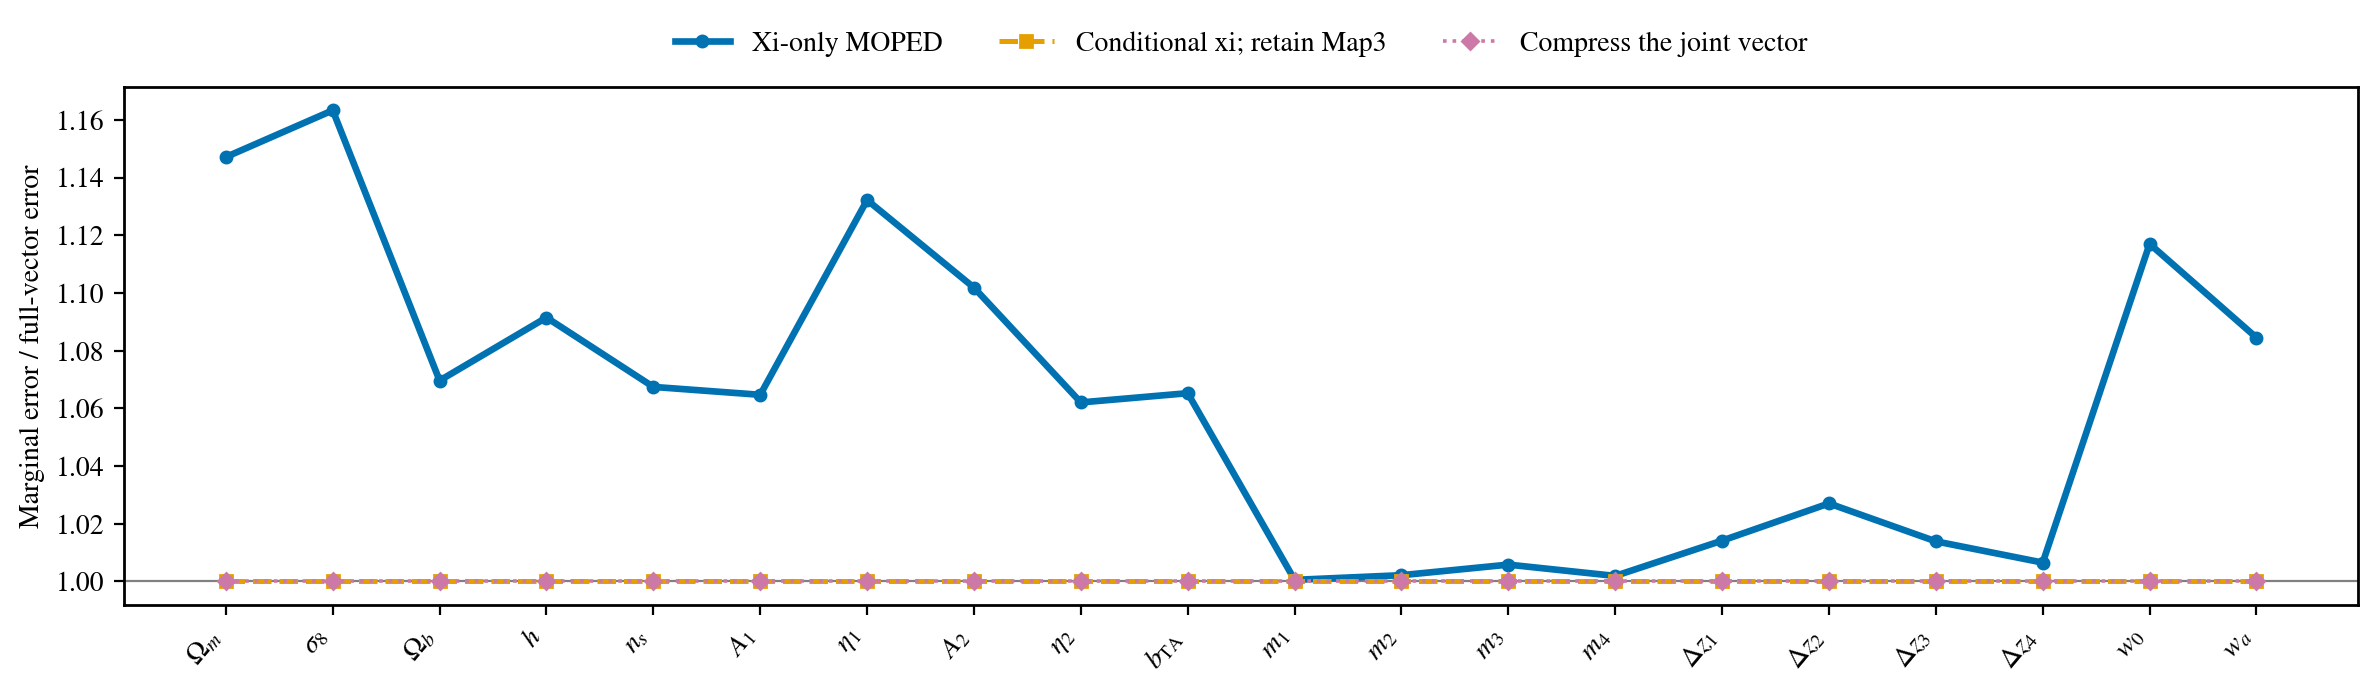

In [5]:
figure, axes = plt.subplots(figsize=(12, 3.6))
styles = {
    "xi_moped": ("Xi-only MOPED", "#0072B2", "o", 2.4, "-"),
    "conditional_xi": ("Conditional xi; retain Map3", "#E69F00", "s", 1.8, "--"),
    "joint": ("Compress the joint vector", "#CC79A7", "D", 1.3, ":"),
}
for mode, (label, color, marker, width, pattern) in styles.items():
    axes.plot(np.arange(len(names)), error_ratios[mode], label=label, color=color,
              marker=marker, markersize=4, linewidth=width, linestyle=pattern)
parameter_labels = [
    r"$\Omega_m$", r"$\sigma_8$", r"$\Omega_b$", r"$h$", r"$n_s$",
    r"$A_1$", r"$\eta_1$", r"$A_2$", r"$\eta_2$", r"$b_{\rm TA}$",
    r"$m_1$", r"$m_2$", r"$m_3$", r"$m_4$",
    r"$\Delta z_1$", r"$\Delta z_2$", r"$\Delta z_3$", r"$\Delta z_4$",
    r"$w_0$", r"$w_a$",
]
axes.set_xticks(ticks=np.arange(len(names)), labels=parameter_labels, rotation=50,
               ha="right")
axes.set_ylabel(ylabel="Marginal error / full-vector error")
axes.axhline(y=1., color="gray", linewidth=.8, zorder=0)
legend = axes.legend(loc="lower center", bbox_to_anchor=(.5, 1.01),
                     ncol=3, frameon=False)
figure.tight_layout()
figure.canvas.draw()
# The external legend must stay above every drawn data point.
legend_box = legend.get_window_extent(figure.canvas.get_renderer())
for line in axes.lines:
    display_points = axes.transData.transform(line.get_xydata())
    assert np.max(display_points[:, 1]) < legend_box.y0
plot_directory = project / "plots" / "compression"
plot_directory.mkdir(parents=True, exist_ok=True)
figure.savefig(fname=plot_directory / "local_errors.png", dpi=160, pad_inches=.15)
figure.savefig(fname=plot_directory / "local_errors.pdf", pad_inches=.15)
plt.show()


## Save the experiment once, and use it consistently

The saved matrix carries the exact input labels. A likelihood picks its
physical rows first, then checks that those labels match the training order,
and then transforms the observed values, every theory vector and both
covariance axes. A compressed row has no single angular separation, so it
carries a mode label rather than an invented physical coordinate.

The first saved basis below is the conditional Gaussian demonstration; the
second trains on the independent diagonal pilot. Neither is the published
compression matrix of Gomes et al. (arXiv:2601.09133): an exact posterior
reproduction would import that matrix and its exact row order instead.

In [6]:
def save_or_verify(basis, destination):
    """Refuse to replace a saved experiment with different arrays or metadata."""
    if destination.exists():
        previous = load_compression(path=destination)
        np.testing.assert_array_equal(x=previous.matrix, y=basis.matrix)
        assert previous.metadata_json == basis.metadata_json
    else:
        basis.save(path=destination)

save_or_verify(basis=bases["conditional_xi"],
               destination=project / "runs" / "conditional_xi_compression.npz")
pilot_noise = np.full(labels.size, 1.e-4)
pilot_noise[kinds == "map3"] = 1.e-8
pilot_covariance = np.diag(pilot_noise**2)
pilot_training = dict(training)
pilot_training["covariance_field"] = "fixed_diagonal_teaching_pilot"
pilot_training["covariance_training_independent"] = True
pilot_training["pilot_noise"] = {"xi": 1.e-4, "map3": 1.e-8}
pilot_basis = fit_compression(
    covariance=pilot_covariance, derivatives=derivatives, labels=labels,
    kind=kinds, mode="conditional_xi", metadata=pilot_training,
)
save_or_verify(basis=pilot_basis,
               destination=project / "runs" / "independent_pilot_compression.npz")
print("Saved fixed matrices with labels, training point and input hash.")


Saved fixed matrices with labels, training point and input hash.


## Finite simulation uncertainty is a separate assumption

The Percival prescription uses the ordinary sample covariance from $N_s$
independent Gaussian mock vectors, and its posterior density carries an
exponent that depends on the number of kept data entries and fitted mean
parameters (Percival, Friedrich, Sellentin and Heavens, arXiv:2108.10402: the
finite-simulation posterior density and its exponent). It has no Hartlap
rescaling. The code counts rows after compression and requires a normalized
data density, so not every $N_s>N_d+4$ configuration passes.

The demonstration uses $N_s=796$ with the independent pilot basis, a local
linear mean, and the fiducial mean as its synthetic datum. The Gaussian-mock,
independence and fixed-covariance assumptions appear explicitly in the code
below. Four footprints cut from one full sky need not be independent, and this
example does not verify that assumption for the Y3 mocks.

Recomputing the Percival exponent after compression defines the compressed
statistical analysis; it is not the marginal of the full-vector t density, and
strong priors or nonlinear responses can change the frequentist coverage
argument. The
[Friedrich–Eifler precision-matrix expansion](https://arxiv.org/abs/1703.07786)
uses simulations differently, and this likelihood must not receive it as a raw
sample covariance.

In [7]:
rows = SurveyRows(kind=kinds, bins=row_bins, angles=row_angles,
                  values=mean, labels=labels)
baseline = {}
for name in names:
    baseline[name] = fiducial[name]

def local_mean(parameters):
    """Evaluate the archived first-order Taylor model, without physical claims."""
    displacement = np.array([parameters[name] - baseline[name] for name in names])
    return mean + derivatives @ displacement

finite = FiniteSimulationLikelihood(
    predict=local_mean, rows=rows, covariance=covariance, parameters=baseline,
    mock_count=796, parameter_count=len(names), compression=pilot_basis,
    assumptions={
        "covariance_kind": "sample",
        "independent_mocks": True,
        "independent_data": True,
        "gaussian_mocks": True,
        "compression_independent": True,
    }, data=mean,
)
point = dict(baseline)
point["a1"] += .1
print("Retained rows:", finite.dimension, "Percival exponent:", finite.exponent)
print("Local fiducial log density:", finite(parameters=baseline))
print("Local displaced log density:", finite(parameters=point))


Retained rows: 100 Percival exponent: 734.8263430637885
Local fiducial log density: 1810.8509231139565
Local displaced log density: 1810.5737985418589


The production CLI loads either fixed matrix through its `compression` section.
[EXAMPLE_NAUTILUS4.yaml](EXAMPLE_NAUTILUS4.yaml) picks the independent pilot
and the finite-simulation prescription explicitly, and its synthetic physical
mean uses the shared TATT prediction. Run `--validate-config` before `--check`;
the notebook launches no sampler.

**Credits.** The compression comparison follows the MOPED construction of
[Heavens, Jimenez and Lahav](https://arxiv.org/abs/astro-ph/9911102), and the
finite-simulation model follows
[Percival, Friedrich, Sellentin and Heavens](https://arxiv.org/abs/2108.10402).
The reproduction targets are the
[methods paper](https://arxiv.org/abs/2503.03964) of Sugiyama and Gomes, the
[TATT paper](https://arxiv.org/abs/2601.09133) of Gomes et al.,
[fastnc](https://github.com/git-sunao/fastnc/tree/tatt), the
[Y3 integrator](https://github.com/rchgomes/3pcf_integrator) and the
[Y6 pipeline](https://github.com/rchgomes/desy6-3pcf); the
[project README](README.md#acknowledgements) carries the acknowledgements.